At each checkpoint the action probabilities mix expected drive and pass failure risk. Half-life bands map the hazard to an interpretable four-level scale. **own derivation; design choice**

## Model and inputs

Let q=P(pass|s), r_d=drive risk, and r_p=Σ_k p(destination k|pass,s)[1−p(success|k,s)]. Then h=(1−q)r_d+q r_p. Because destination probabilities sum to one, r_p=1−Σ_k p_k p(success|k). The code calls Σ_k p_k p(success|k) `rppcf`; this is our transition-weighted pass-success aggregate. Spearman's source calls the underlying control model the Potential Pitch Control Field (PPCF), and does not establish `rPPCF` as a universal name for this aggregate [@spearman2018beyond]. **own derivation**. Band cutoffs use h=1−2^(−1/n), for n=1,2,4,8. The operational labels are None, Low, Medium, High; the fifth h>0.5 band is intentionally not used. **design choice**.

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope and model limits

Composition is the repository’s own model definition; discrete-time hazard context [@singer2003].

The composed quantity is the raw next-action hazard from the stored branch components. It is conditional on component definitions and outputs; the vignette does not add a post-hoc calibrator. The band names discretize this hazard for interpretation. **model scope; design choice**


Half-life cutoffs (computed): {1: 0.5, 2: 0.2928932188134524, 4: 0.1591035847462855, 8: 0.08299595679532878}
Bands present in this toy curve (computed): ['Medium', 'High']


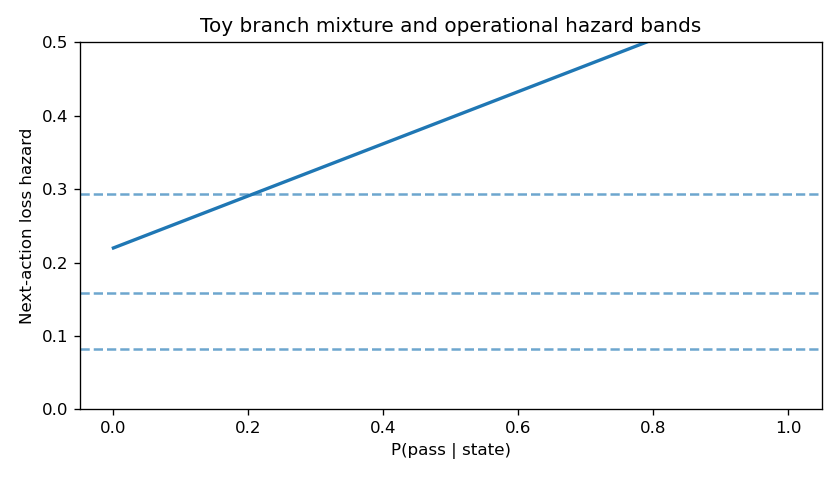

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PRESS.utils.hazard import compute_hazard_raw
from PRESS.utils.possession import hazard_band_thresholds, hazard_to_band

drive_risk=0.22
transition=np.array([0.25,0.50,0.25])
pass_success=np.array([0.70,0.40,0.20])
p_pass=np.linspace(0,1,101)
hazards=np.array([compute_hazard_raw(drive_risk,transition,pass_success,q)[0] for q in p_pass])
thresholds=hazard_band_thresholds()
operational=[thresholds[n] for n in (8,4,2)]
bands=hazard_to_band(hazards)
fig,ax=plt.subplots(figsize=(7,4)); ax.plot(p_pass,hazards,lw=2)
for cutoff in operational: ax.axhline(cutoff,ls="--",alpha=.65)
ax.set(xlabel="P(pass | state)",ylabel="Next-action loss hazard",ylim=(0,.5),title="Toy branch mixture and operational hazard bands"); fig.tight_layout()
out=Path("figures/vignette_05_hazard_bands.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))
print("Half-life cutoffs (computed):", thresholds)
print("Bands present in this toy curve (computed):", sorted(set(bands),key=list(("None","Low","Medium","High")).index))

## Use the package on a selected frame

This standalone example initializes one match, selects a team possession and a usable tracking frame, and calls the public API for this task. The match and xT inputs are **synthetic**. Small grids make the example quick and change the model inputs; use the research defaults for analysis. Replace the demo initializer with `PRESS.from_skillcorner(...)` from the [match guide](../../usage.qmd) to use processed local files.


In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
result = model.compute_frame(frame_id, xT_grid,
    ppcf_kwargs={"r_max": 12, "step": 6}, bcos_kwargs={"r_max": 8, "step": 4})
hazard = model.get_hazard_result(frame_id)["Hazard"]
print("hazard:", hazard, "band:", hazard_to_band(hazard))


hazard: 0.012514264786956159 band: None
